# Import a Biacore Cycle/sample text export

Import **`biacore_cycle_sample.tsv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses a full-resolution selection committed with the repository;
it fits the published one-site model and compares its parameters with the author report. No data download is required.

**Data origin:** [Duke TitrationAnalysis T200 example](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Example%20T200%20Chip%201%20Channel%202.txt). TitrationAnalysis tool, Kan Li and S Moses Dennison, Duke University. [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](data/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/TitrationAnalysis-LICENSE).

In [1]:
from pathlib import Path
import sys
import warnings
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

# Works from the repository root, notebooks/, or docs/notebooks/.
cwd = Path.cwd().resolve()
repo_root = next(
    path for path in (cwd, *cwd.parents)
    if (path / "src" / "pykingenie").is_dir()
    and (path / "test_files" / "spr_exports").is_dir()
)
for path in [repo_root / "src", repo_root / "notebooks"]:
    sys.path.insert(0, str(path))
from pykingenie import detect_file_format, SprTextExperiment, KineticsAnalyzer, plot_plate_info

plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
data_file = repo_root / "notebooks" / "data" / "spr_exports" / "biacore_cycle_sample.tsv"
print("Input:", data_file.name)
fit_metadata = json.loads((data_file.parent / "fit_metadata.json").read_text())[data_file.stem]

Input: biacore_cycle_sample.tsv


## File layout and representative selection

Tab-separated pairs for cycles 20, 21, and 22 of the same AE.A244 series, selected to show clear responses. The verbatim labels are `50 µg`, `100 µ`, and `200 µ`. The original Windows-1252 text is converted to UTF-8; all finite time/response pairs are retained at their recorded sampling resolution.

These mass/truncated labels do not establish molar units. The reader receives verified concentrations explicitly from the companion sheet below. The source has eight incomplete or non-finite pairs in cycle 21. Only those eight pairs are omitted from this teaching export. There is no interpolation, smoothing or response correction.

The curve exports alone do not establish injection-event timing. The original
companion sample sheet now provides the phase timings used below.
The sensorgram plot rejoins all partitions on the original time grid.
Boundaries are seconds, and association is
`[association_start, association_end)`.

Concentrations are supplied explicitly from the original sample sheet.
`sample_id` is the analyte identity supplied by that sample sheet.

In [2]:
association_start = fit_metadata["association_start"]
association_end = fit_metadata["association_end"]

print("Detected layout:", detect_file_format(data_file))

experiment = SprTextExperiment("biacore_cycle_sample")
with warnings.catch_warnings(record=True) as messages:
    warnings.simplefilter("always", UserWarning)
    experiment.read_file(
        data_file,
        association_start=association_start,
        association_end=association_end,
        decimal='.',
        time_unit="s",
        sample_id=fit_metadata["analyte"],
        concentrations=fit_metadata["concentrations"],
        concentration_unit="uM",
    )
for message in messages:
    print(message.message)
print(f"Imported {experiment.no_sensors} measured curves; {experiment.no_steps} API phases.")
assert experiment.traces_loaded and experiment.no_sensors == 3

Detected layout: spr_text
Imported 3 measured curves; 3 API phases.


## Available curve information

Each measured curve becomes a sensor in the experiment object. Its complete
original label remains in `sensor_names`. The following table extracts only
the header/row-label fields present in this specific example file.

In [3]:
curve_ids = [f"Curve {i + 1}" for i in range(experiment.no_sensors)]
labels = pd.Series(experiment.sensor_names, name="Exported label")
header_info = labels.str.extract('Cycle:\\s*(?P<Cycle>\\d+)\\s+(?P<Sample_label>\\S+)\\s+(?P<Concentration_label>.+)$')
header_info.insert(0, "Curve", curve_ids)
display(header_info)
display(labels.to_frame())
plot_labels = header_info["Concentration_label"].tolist()

,Curve,Cycle,Sample_label,Concentration_label
0,Curve 1,20,AE.A244,50 µg
1,Curve 2,21,AE.A244,100 µ
2,Curve 3,22,AE.A244,200 µ


,Exported label
0,Cycle: 20 AE.A244 50 µg
1,Cycle: 21 AE.A244 100 µ
2,Cycle: 22 AE.A244 200 µ


## Verified concentration metadata

The original companion sample sheet supplies **molar concentrations**, independent
of the ambiguous export labels. The explicit mapping in `fit_metadata.json`
converts the author's values from M to µM. These concentrations are passed to the
reader; no molecular weight or interpretation of a truncated unit is guessed.
The fit section below displays the source and mapping.

In [4]:
concentration_info = experiment.ligand_conc_df.copy()
concentration_info.insert(0, "Curve", curve_ids)
display(concentration_info[["Curve", "Concentration_micromolar", "SampleID"]])
assert concentration_info["Concentration_micromolar"].notna().all()

,Curve,Concentration_micromolar,SampleID
0,Curve 1,0.8868,AE.A244
1,Curve 2,1.7740,AE.A244
2,Curve 3,3.5470,AE.A244


## Plate information, when available

Cycle numbers and the `AE.A244` sample label do not establish plate coordinates. No plate layout is present in this text export.

The conditional cell below uses `plot_plate_info` only when the experiment
actually contains the required plate metadata. It prints a message for this
file rather than assigning artificial well positions.

In [5]:
analyzer = KineticsAnalyzer()
analyzer.add_experiment(experiment, experiment.name)
plate_fields = (
    "sample_row", "sample_column", "sample_type", "sample_id", "sample_conc_labeled"
)
have_plate_info = all(
    getattr(experiment, field) is not None
    and len(getattr(experiment, field)) > 0
    for field in plate_fields
)
if have_plate_info:
    display(pd.DataFrame({field: getattr(experiment, field) for field in plate_fields}))
    plot_plate_info(analyzer, experiment.name).show()
else:
    print("No plate-well coordinates are available in this export; no plate plot is created.")

No plate-well coordinates are available in this export; no plate plot is created.


## Imported sensorgrams

Every finite source observation in the selected curves is plotted at its original
time. No resampling, smoothing or baseline subtraction is applied. Lines break
across gaps larger than three median sampling intervals. Legend entries use the
original concentration labels or cycle/flow-cell identifiers shown above.

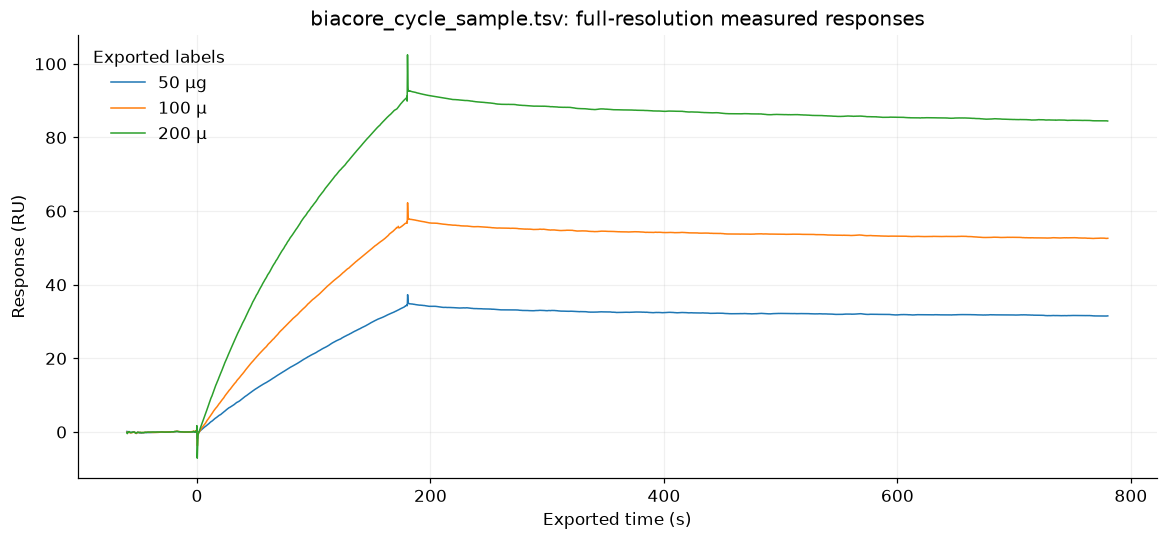

In [6]:
fig, ax = plt.subplots(figsize=(10.5, 4.8), constrained_layout=True)
axes = [ax]
for i, label in enumerate(plot_labels):
    time = np.concatenate(experiment.xs[i])
    response = np.concatenate(experiment.ys[i])
    breaks = np.flatnonzero(np.diff(time) > 3 * np.median(np.diff(time))) + 1
    segments = np.split(np.arange(len(time)), breaks)
    for axis in axes:
        for j, indices in enumerate(segments):
            axis.plot(time[indices], response[indices], color=f"C{i}", linewidth=1,
                      label=label if j == 0 else None)
for axis in axes:
    axis.set(xlabel="Exported time (s)", ylabel="Response (RU)")
    axis.legend(frameon=False, title="Exported labels")
    axis.grid(alpha=0.18)
ax.set_title("biacore_cycle_sample.tsv: full-resolution measured responses")
plt.show()

## Check the retained points and import partitions

The original times remain in `xs`; `ys` contains the corresponding measured
responses. Duke phase times come from the companion metadata. The rstoolbox and
binning phase boundaries remain provisional. For binning, post-event data include
later protocol steps; the fit below uses only an explicitly limited early episode.

In [7]:
imported_points = pd.DataFrame([
    {
        "Curve": curve_ids[i],
        "Baseline points": len(experiment.xs[i][0]),
        "Association points": len(experiment.xs[i][1]),
        "Dissociation points": len(experiment.xs[i][2]),
        "Total points": sum(len(step) for step in experiment.xs[i]),
        "First exported time (s)": np.concatenate(experiment.xs[i])[0],
        "Last exported time (s)": np.concatenate(experiment.xs[i])[-1],
    }
    for i in range(experiment.no_sensors)
])
display(imported_points)
display(experiment.df_steps[["Name", "Type", "Start"]])

,Curve,Baseline points,Association points,Dissociation points,Total points,First exported time (s),Last exported time (s)
0,Curve 1,601,1800,6003,8404,-60.06,780.24
1,Curve 2,600,1792,6003,8395,-59.96,780.24
2,Curve 3,600,1800,6002,8402,-59.96,780.14


,Name,Type,Start
0,Baseline,BASELINE,-60.06
1,Association,ASSOC,0.00
2,Dissociation,DISASSOC,180.00


All finite source observations in the teaching selection remain available in the import. The following fit uses an aligned copy of these observations.

## Published one-site model

The original T200 sample sheet specifies association **0–180 s**, dissociation
**180–780 s**, regeneration, and association bulk shifts. Fit a **one-site
Langmuir model with local Rmax and one association-only RI offset per curve**,
matching the model/settings in author report fitting #1. The selected cycles
20–22 have concentrations **0.8868, 1.774, 3.547 µM**.

Reference: [Li et al., TitrationAnalysis](https://pmc.ncbi.nlm.nih.gov/articles/PMC10667272/) and the [author report](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Titration%20Analysis_T200_Report_Example.csv). The original CSV is included locally with provenance in [SOURCES.md](data/spr_exports/SOURCES.md).

The author report fits **five curves**; this notebook retains the **three representative imported curves**. No alternative models or model selection are run.

## Align association before fitting

Call `align_association(inplace=True, npoints=10)` on a copy. It subtracts the
mean of the last 10 baseline points from every phase without changing time.
The raw experiment and import plot above remain unchanged. No second baseline
subtraction is applied by the fitting helper.

Exclude 3 s around injection transitions and fit at most one original point
per second. There is no interpolation, smoothing or averaging of fitted points.
Carterra retains its slower native sampling. The physical association end state
is propagated to dissociation even when transition observations are excluded.

In [8]:
from copy import deepcopy

# Preserve the imported experiment and explicitly align every fitting curve.
fit_experiment = deepcopy(experiment)
association_step = int(experiment.df_steps.index[experiment.df_steps["Type"] == "ASSOC"][0])
alignment_points = 10
alignment_offsets = {
    name: float(np.mean(experiment.ys[i][association_step - 1][-alignment_points:]))
    for i, name in enumerate(experiment.sensor_names)
}
fit_experiment.align_association(inplace=True, npoints=alignment_points)
fit_metadata = deepcopy(fit_metadata)
fit_metadata["association_alignment"] = {
    "method": "align_association",
    "npoints": alignment_points,
    "offsets_by_sensor": alignment_offsets,
}
aligned_baseline_means = [
    float(np.mean(fit_experiment.ys[i][association_step - 1][-alignment_points:]))
    for i in range(fit_experiment.no_sensors)
]
assert np.allclose(aligned_baseline_means, 0, atol=1e-10)
display(pd.DataFrame({
    "Curve": curve_ids,
    "Subtracted pre-association mean": list(alignment_offsets.values()),
    "Aligned pre-association mean": aligned_baseline_means,
}))

,Curve,Subtracted pre-association mean,Aligned pre-association mean
0,Curve 1,0.041200,2.775558e-18
1,Curve 2,0.302471,2.220446e-17
2,Curve 3,0.481542,-8.881784e-17


In [9]:
from spr_fitting import fit_one_site, parameter_table, literature_comparison, plot_fit

fit = fit_one_site(fit_experiment, fit_metadata)
print(f"One-site model; local Rmax; {fit['n']} fitted observations; {fit['k']} parameters.")
print(f"Fit RMSE: {fit['rmse']:.4g} RU")

# Optional numerical export:
# from spr_fitting import save_report
# save_report(fit, "my_one_site_fit.json")

One-site model; local Rmax; 2313 fitted observations; 8 parameters.
Fit RMSE: 0.4277 RU


## One-site fitted sensorgrams and residuals

Thin solid lines are the association-aligned observations; dashed lines are the
one-site fit. Grey bands show the transition masks. Residuals are data minus fit.

**Check the published figure:** [Author fitted-sensorgram PDF](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Titration%20Analysis_T200_Sensorgram_Example.pdf).
Locate Chip 1 / Channel 2, fitting #1 (**local Rmax**); ligand CH31, analyte AE.A244. The author report shows five curves; this notebook fits three selected curves.

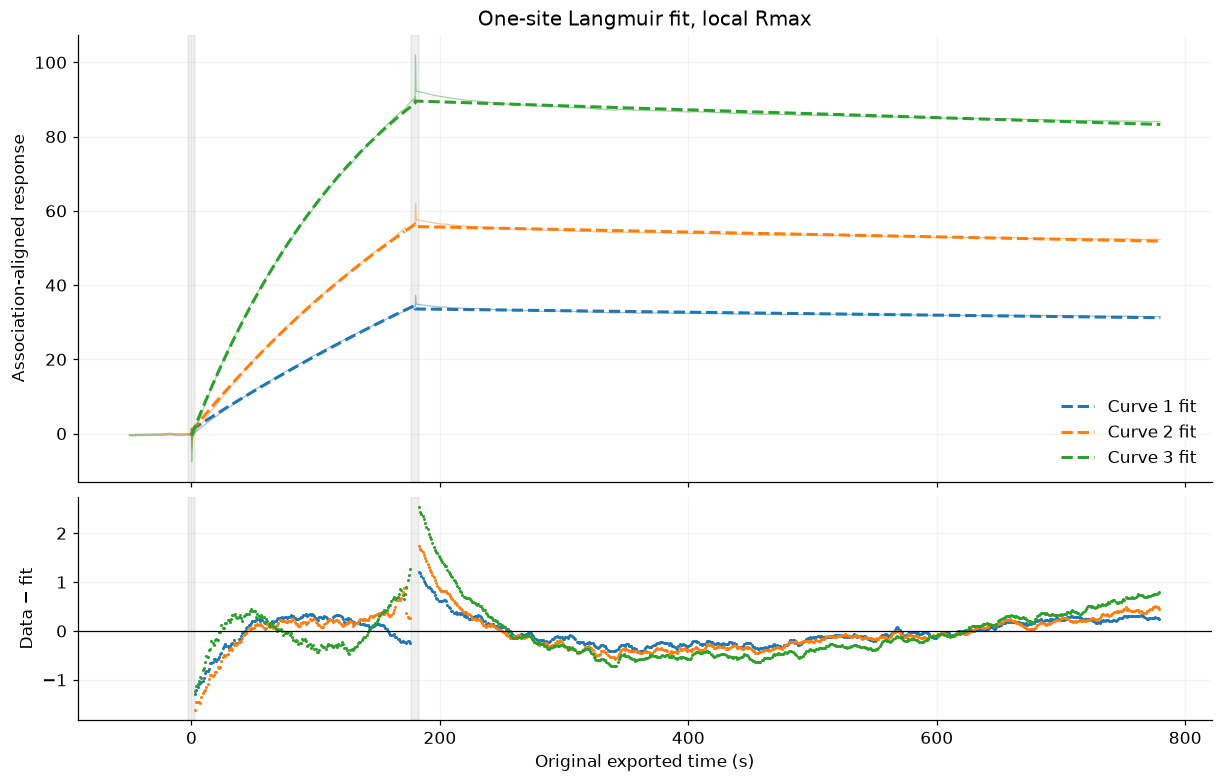

In [10]:
fig_fit = plot_fit(fit)
plt.show()

## Fitted parameters and published comparison

Rmax values describe total physical binding capacity, including material already
bound before Carterra association. RI values are association-only offsets.
The comparison uses the author report row identified above, with kon in
M⁻¹ s⁻¹, koff in s⁻¹ and Kd in nM. The difference is relative to the published value.

**Check the published numbers:** [Original parameter table (PDF)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Titration%20Analysis_T200_Report_Example.pdf) or [machine-readable values (CSV)](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Titration%20Analysis_T200_Report_Example.csv).
Use Chip 1 / Channel 2, fitting #1 (**local Rmax**); ligand CH31, analyte AE.A244. These are the values in the Published column below.

In [11]:
display(parameter_table(fit).style.format({"Estimate": "{:.5g}"}))
display(literature_comparison(fit).style.format({
    "Published": "{:.5g}", "This notebook": "{:.5g}", "Difference (%)": "{:+.2f}",
}))

,Parameter,Unit,Estimate
0,kon,M⁻¹ s⁻¹,1844.1
1,koff,s⁻¹,0.00012177
2,Kd,nM,66.032
3,Rmax_1,RU,133
4,Rmax_2,RU,126.51
5,Rmax_3,RU,130.58
6,RI_1,RU,0.97865
7,RI_2,RU,0.59398
8,RI_3,RU,-0.5978


,Parameter,Unit,Published,This notebook,Difference (%)
0,kon,M⁻¹ s⁻¹,1812.1,1844.1,+1.77
1,koff,s⁻¹,0.00011912,0.00012177,+2.23
2,Kd,nM,65.736,66.032,+0.45


## Scope of the comparison

The published one-site result is Kd **65.74 nM**. This notebook gives approximately
**66.03 nM**; kon and koff differ by about **1.8% and 2.2%**. This is agreement
for the same source interaction with a smaller curve selection, not an exact
reproduction of the authors' complete fit.

See [SPR_FITTING.md](SPR_FITTING.md) for the retained model, preprocessing and reference reports. No mechanistic conclusion is drawn from agreement with a reference fit.